# Fase C – Analisi intra-layer (RQ1)

**RQ1: come sono organizzati strutturalmente gli utenti in ciascun mercato?**

Segue i blocchi della fase C del piano: struttura, hub, comunità, categorie, profili. Richiede le tabelle create da `fase_b_reti.ipynb`.
I risultati principali sono sulla rete `senza_contratti`, perché le ipotesi riguardano gli attori; la rete `completa` serve per misurare quanto contano i contratti.

## 0. Dati

In [1]:
import random
import numpy as np
import pandas as pd
import scipy.sparse as sp
import igraph as ig
import leidenalg as la
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from analisi_utils import *

stile()
N_NULL = 50          # istanze del modello nullo (la lezione chiede molte più di 30)
N_PERM = 500         # permutazioni per l'arricchimento delle categorie
TOP_COMUNITA = 12    # comunità mostrate nelle heatmap e nei profili
MIN_NFT_CAT = 200    # una categoria entra nella heatmap se ha almeno questi NFT nel layer
PRINCIPALE = 'senza_contratti'

GRAFI = {v: carica_grafi(v) for v in VARIANTI}
contratti = set(pd.read_parquet(DATI / 'contratti_identificati.parquet').wallet)
print({v: {NOME[l]: (g.vcount(), g.ecount()) for l, g in G.items()} for v, G in GRAFI.items()})

{'senza_contratti': {'Username': (346133, 740238), 'Numeri': (133355, 308246)}, 'completa': {'Username': (554965, 1148787), 'Numeri': (149031, 339635)}}


## 1. Struttura

Metriche sui wallet con almeno un arco. La **centralizzazione di Freeman** vale 0 se tutti i wallet hanno lo stesso numero di contatti e 1 se la rete è una stella.

In [2]:
def centralizzazione(u):
    k = np.array(u.degree())
    n = len(k)
    return (k.max() - k).sum() / ((n - 1) * (n - 2))

def struttura(g):
    h = attivi(g)
    u = non_orientato(h)
    s = np.array(h.strength(mode='all', weights='weight'), dtype=float)
    ordinati = np.sort(s)
    comp = np.array(g.connected_components('weak').sizes())
    comp_attivi = comp[comp > 1]
    return {
        'wallet (nodi)': g.vcount(), 'wallet con archi': h.vcount(), 'archi (coppie)': g.ecount(),
        'passaggi': int(sum(g.es['weight'])), 'componenti (senza isolati)': len(comp_attivi),
        'componente gigante (% wallet con archi)': comp_attivi.max() / h.vcount(), 'densità': h.density(),
        'reciprocità': h.reciprocity(), 'clustering medio': u.transitivity_avglocal_undirected(mode='zero'),
        'transitività globale': u.transitivity_undirected(), 'grado medio (in + out)': np.mean(h.degree()),
        'grado massimo': max(h.degree()), 'forza massima': int(s.max()), 'centralizzazione di Freeman': centralizzazione(u),
        'Gini della forza': gini(s), 'quota passaggi del top 1%': ordinati[-max(1, len(s) // 100):].sum() / s.sum(),
        'quota passaggi del top 10%': ordinati[-max(1, len(s) // 10):].sum() / s.sum(),
    }

tab = pd.DataFrame({(NOME_VARIANTE[v], NOME[l]): struttura(g) for v, G in GRAFI.items() for l, g in G.items()})
salva_tabella(tab, 'c_struttura')
leggibile(tab)

senza contratti             completa          
                                               Username    Numeri   Username    Numeri
wallet (nodi)                                   346.133   133.355    554.965   149.031
wallet con archi                                316.639   124.438    525.505   140.115
archi (coppie)                                  740.238   308.246  1.148.787   339.635
passaggi                                      1.470.602   610.955  1.923.120   656.071
componenti (senza isolati)                        8.357     1.211      8.314     1.200
componente gigante (% wallet con archi)           0.923     0.976      0.954     0.979
densità                                        7.38e-06  1.99e-05   4.16e-06  1.73e-05
reciprocità                                       0.177     0.175      0.416     0.177
clustering medio                                  0.109     0.116     0.0846     0.164
transitività globale                            0.00273    0.0101    0.00148   0.00661
grado medio (in + out)                             4.68      4.95       4.37      4.85
grado massimo                                    20.522     5.838     21.247     6.208
forza massima                                    51.296    12.642     51.654    13.156
centralizzazione di Freeman                      0.0615    0.0381     0.0404    0.0442
Gini della forza                                  0.747     0.797      0.706     0.789
quota passaggi del top 1%                         0.375       0.5      0.364     0.512
quota passaggi del top 10%                        0.686     0.778      0.673     0.775

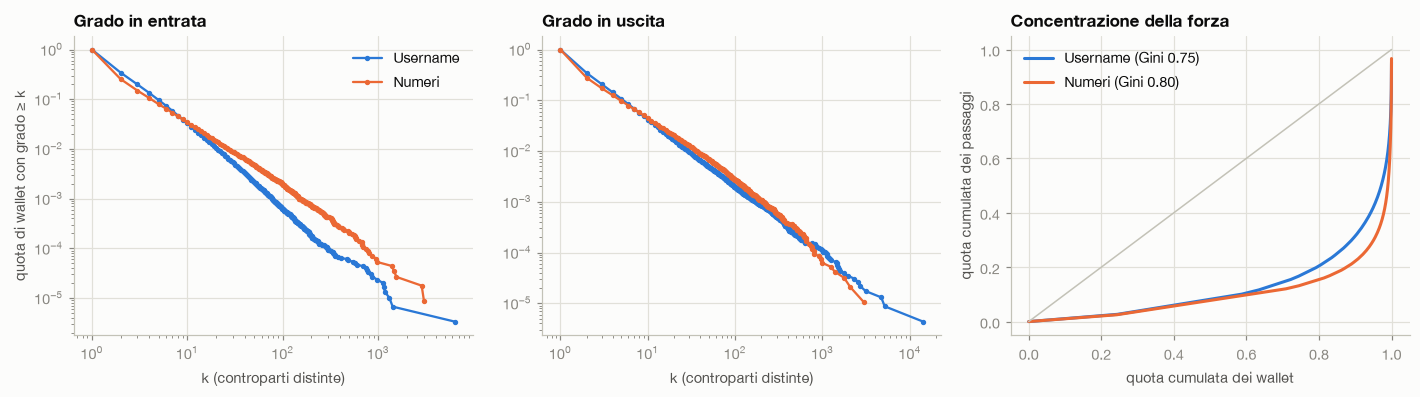

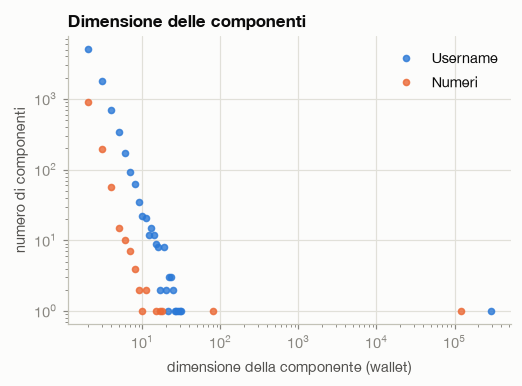

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
G = GRAFI[PRINCIPALE]
for ax, (titolo, modo) in zip(axes, [('Grado in entrata', 'in'), ('Grado in uscita', 'out')]):
    for l, g in G.items():
        k = np.array(g.degree(mode=modo))
        kk, pp = ccdf(k[k > 0])
        ax.loglog(kk, pp, color=COLORI[l], label=NOME[l], marker='o', markersize=2.5, linewidth=1.5)
    ax.set_title(titolo)
    ax.set_xlabel('k (controparti distinte)')
axes[0].set_ylabel('quota di wallet con grado ≥ k')
axes[0].legend()
for l, g in G.items():
    x = np.sort(np.array(attivi(g).strength(mode='all', weights='weight'), dtype=float))
    c = np.r_[0, np.cumsum(x) / x.sum()]
    q = np.linspace(0, 1, len(c))
    passo = max(1, len(c) // 2000)
    axes[2].plot(q[::passo], c[::passo], color=COLORI[l], label=f'{NOME[l]} (Gini {gini(x):.2f})')
axes[2].plot([0, 1], [0, 1], color='#c3c2b7', linewidth=1)
axes[2].set_title('Concentrazione della forza')
axes[2].set_xlabel('quota cumulata dei wallet')
axes[2].set_ylabel('quota cumulata dei passaggi')
axes[2].legend(loc='upper left')
fig.tight_layout()
salva_figura(fig, 'c_gradi_e_concentrazione')
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 3.4))
for l, g in G.items():
    dim = np.array(g.connected_components('weak').sizes())
    dim = dim[dim > 1]
    kk, conte = np.unique(dim, return_counts=True)
    ax.loglog(kk, conte, color=COLORI[l], label=NOME[l], linestyle='', marker='o', markersize=4, alpha=0.8)
ax.set_xlabel('dimensione della componente (wallet)')
ax.set_ylabel('numero di componenti')
ax.set_title('Dimensione delle componenti')
ax.legend()
salva_figura(fig, 'c_componenti')
plt.show()

### Confronto con il modello nullo

**Configuration model sui passaggi** (lezione 8, un layer alla volta).
* *Assunzione*: le controparti degli scambi sono casuali.
* *Invarianti*: per ogni wallet, il numero di passaggi ricevuti e ceduti.
* *Rimescolato*: chi scambia con chi.
* *Metriche*: reciprocità, clustering medio, modularità di Louvain.

In [4]:
def metriche(g, seed):
    u = non_orientato(g) if len(g.es) and 'n_vendite' in g.es.attributes() else g.as_undirected(mode='collapse', combine_edges={'weight': 'sum'})
    return {'reciprocità': g.reciprocity(), 'clustering medio': u.transitivity_avglocal_undirected(mode='zero'),
            'modularità (Louvain)': modularita_louvain(u, seed)}

righe = []
for l, g in GRAFI[PRINCIPALE].items():
    oss = metriche(attivi(g), SEED)
    nullo = pd.DataFrame([metriche(nullo_configurazione(g, SEED + i), SEED + i) for i in range(N_NULL)])
    for m, v in oss.items():
        righe.append({'layer': NOME[l], 'metrica': m, 'osservato': v, 'media nullo': nullo[m].mean(), 'std nullo': nullo[m].std(ddof=1),
                      'z': z_score(v, nullo[m]), 'p empirico': p_empirico(v, nullo[m])})
tab = pd.DataFrame(righe).set_index(['layer', 'metrica'])
salva_tabella(tab, 'c_confronto_nullo')
tab

osservato  media nullo  std nullo     z  p empirico
layer    metrica                                                                  
Username reciprocità              0.1775      0.01798  0.0001199  1330     0.01961
         clustering medio         0.1094      0.04716  0.0002812 221.3     0.01961
         modularità (Louvain)     0.7998        0.256  0.0002409  2257     0.01961
Numeri   reciprocità              0.1748      0.05447  0.0003594 334.9     0.01961
         clustering medio         0.1159       0.1068   0.000716 12.71     0.01961
         modularità (Louvain)     0.6815       0.2318  0.0003021  1489     0.01961

## 2. Hub

Classifiche per grado in entrata, grado in uscita, forza e PageRank, poi due controlli di stabilità: rispetto ai pesi e rispetto alla rimozione dei contratti. Gli indirizzi sono abbreviati: nel report non vanno nomi di wallet.

grado_in  grado_out     forza  pagerank
layer    wallet                                              
Username 0:cf01d60c…      6339      14183  5.13e+04  0.009492
         0:6c9adfdd…      1421       2325 1.013e+04  0.003585
         0:d83bce88…       604       1566      8117  0.002526
         0:33729d06…       852       1572      5369  0.001685
         0:11920dc1…      1120       4709 1.254e+04  0.001611
         0:2e09876a…      1313         83      4968  0.001541
         0:03b23f2c…       747       1746      6907    0.0014
         0:c0a51d98…       691       1092      4159  0.001374
         0:3151e8e2…        23        493      3781  0.001251
         0:6aa65f58…       873       1945      5783  0.001179
Numeri   0:3d8c8790…      3022       2073 1.264e+04    0.0108
         0:9a7752ca…      2861       2977      7549  0.009717
         0:3142088f…      1466       1239 1.033e+04  0.005998
         0:b6e179b3…       798        952      2012  0.003459
         0:09fe8bad…      1382       1386      6520   0.00299
         0:74178c40…       973        600      5714  0.002936
         0:67df5dab…       559        311      2873  0.002912
         0:d83bce88…       567        756      3675  0.002725
         0:0c1b9782…      1554        102      3586   0.00269
         0:d2912ff4…       682        642      7527  0.002621

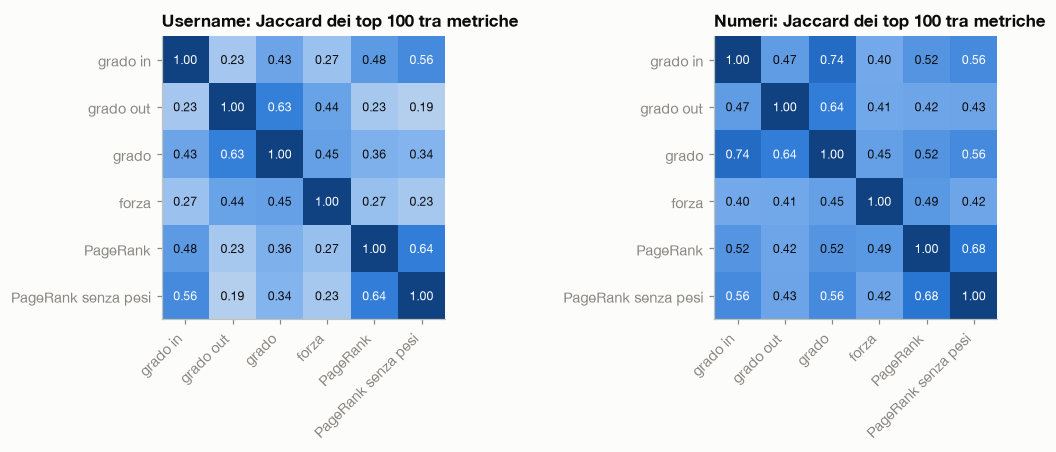

contratti identificati nei top 100 della rete completa  Jaccard completa / senza contratti  Spearman completa / senza contratti
layer    metrica                                                                                                                                                        
Username grado                                                                                4                              0.7699                                0.999
         forza                                                                                4                              0.7699                               0.9993
         PageRank                                                                             5                              0.4925                               0.9739
         PageRank con pesi / senza pesi                                                     NaN                              0.6393                               0.9527
Numeri   grado                                                                                3                              0.8519                               0.9979
         forza                                                                                5                              0.8182                               0.9982
         PageRank                                                                             4                              0.7699                               0.9907
         PageRank con pesi / senza pesi                                                     NaN                              0.6807                               0.9589

In [5]:
def centralita(g):
    return pd.DataFrame({'wallet': g.vs['name'], 'layer': g['layer'], 'grado_in': g.degree(mode='in'), 'grado_out': g.degree(mode='out'),
                         'grado': g.degree(mode='all'), 'forza_in': g.strength(mode='in', weights='weight'),
                         'forza_out': g.strength(mode='out', weights='weight'), 'forza': g.strength(mode='all', weights='weight'),
                         'pagerank': g.pagerank(weights='weight'), 'pagerank_senza_pesi': g.pagerank()})

CENTR = {v: {l: centralita(g) for l, g in G.items()} for v, G in GRAFI.items()}
for v in VARIANTI:
    pd.concat(CENTR[v].values()).to_parquet(cartella_variante(v) / 'centralita.parquet')

METRICHE = ['grado_in', 'grado_out', 'grado', 'forza', 'pagerank', 'pagerank_senza_pesi']
NOMI_M = {'grado_in': 'grado in', 'grado_out': 'grado out', 'grado': 'grado', 'forza': 'forza', 'pagerank': 'PageRank', 'pagerank_senza_pesi': 'PageRank senza pesi'}
def top(df, m, k=100):
    return set(df.nlargest(k, m).wallet)
def jaccard(a, b):
    return len(a & b) / len(a | b)

K_TOP = 100
righe = []
for l in LAYERS:
    c = CENTR[PRINCIPALE][l]
    r = c.nlargest(10, 'pagerank')
    righe.append(r.assign(layer=NOME[l], wallet=r.wallet.map(corto))[['layer', 'wallet', 'grado_in', 'grado_out', 'forza', 'pagerank']])
display(pd.concat(righe).set_index(['layer', 'wallet']))
pd.concat([CENTR[PRINCIPALE][l].nlargest(100, m).assign(metrica=m, wallet=lambda d: d.wallet.map(corto))[['layer', 'metrica', 'wallet', m]].rename(columns={m: 'valore'})
           for l in LAYERS for m in METRICHE]).to_csv(TABELLE / 'c_hub_top100.csv', index=False)

fig, axes = plt.subplots(1, len(LAYERS), figsize=(5.2 * len(LAYERS), 4.2))
ramp = LinearSegmentedColormap.from_list('blu', ['#f0efec', '#86b6ef', '#2a78d6', '#104281'])
for ax, l in zip(axes, LAYERS):
    c = CENTR[PRINCIPALE][l]
    mat = np.array([[jaccard(top(c, a, K_TOP), top(c, b, K_TOP)) for b in METRICHE] for a in METRICHE])
    ax.imshow(mat, vmin=0, vmax=1, cmap=ramp)
    ax.set_xticks(range(len(METRICHE)), [NOMI_M[m] for m in METRICHE], rotation=45, ha='right')
    ax.set_yticks(range(len(METRICHE)), [NOMI_M[m] for m in METRICHE])
    ax.grid(False)
    for i in range(len(METRICHE)):
        for j in range(len(METRICHE)):
            ax.text(j, i, f'{mat[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if mat[i, j] > 0.55 else INK)
    ax.set_title(f'{NOME[l]}: Jaccard dei top {K_TOP} tra metriche')
fig.tight_layout()
salva_figura(fig, 'c_hub_jaccard_metriche')
plt.show()

righe = []
for l in LAYERS:
    p, f = CENTR[PRINCIPALE][l], CENTR['completa'][l]
    for m in ['grado', 'forza', 'pagerank']:
        tf = top(f, m, K_TOP)
        righe.append({'layer': NOME[l], 'metrica': NOMI_M[m], f'contratti identificati nei top {K_TOP} della rete completa': len(tf & contratti),
                      'Jaccard completa / senza contratti': jaccard(tf, top(p, m, K_TOP)),
                      'Spearman completa / senza contratti': f.merge(p, on='wallet')[[m + '_x', m + '_y']].corr(method='spearman').iloc[0, 1]})
    righe.append({'layer': NOME[l], 'metrica': 'PageRank con pesi / senza pesi', 'Jaccard completa / senza contratti': jaccard(top(p, 'pagerank', K_TOP), top(p, 'pagerank_senza_pesi', K_TOP)),
                  'Spearman completa / senza contratti': p[['pagerank', 'pagerank_senza_pesi']].corr(method='spearman').iloc[0, 1]})
tab = pd.DataFrame(righe).set_index(['layer', 'metrica'])
salva_tabella(tab, 'c_hub_stabilita')
tab

## 3. Comunità

**Rappresentazione dichiarata**: grafo non orientato dei wallet con archi, peso = passaggi nelle due direzioni. La partizione di riferimento è **Leiden con risoluzione 1**; la sensibilità confronta Louvain e altre risoluzioni, misurando quanto le partizioni somigliano a quella di riferimento (NMI e ARI). Le comunità si estraggono dai soli collegamenti: le categorie entrano dopo, per interpretarle.

In [6]:
def leiden(u, risoluzione=1.0, seed=SEED):
    return np.array(la.find_partition(u, la.RBConfigurationVertexPartition, weights='weight', resolution_parameter=risoluzione,
                                      n_iterations=2, seed=seed).membership)

def per_dimensione(m):
    # rinumera le comunità: 0 è la più grande
    valori, inverso, conte = np.unique(m, return_inverse=True, return_counts=True)
    rango = np.argsort(np.argsort(-conte))
    return rango[inverso]

righe, PARTIZIONI = [], {}
for v in VARIANTI:
    for l, g in GRAFI[v].items():
        h = attivi(g)
        u = non_orientato(h)
        rif = per_dimensione(leiden(u))
        pd.DataFrame({'wallet': u.vs['name'], 'layer': l, 'comunita': rif}).to_parquet(cartella_variante(v) / f'comunita_{FILE[l]}.parquet')
        PARTIZIONI[(v, l)] = (u, rif)
        if v != PRINCIPALE:
            continue
        random.seed(SEED)
        prove = {'Leiden, risoluzione 1': rif, 'Leiden, risoluzione 0,5': leiden(u, 0.5), 'Leiden, risoluzione 2': leiden(u, 2.0),
                 'Leiden, altro seed': leiden(u, 1.0, SEED + 1), 'Louvain': np.array(u.community_multilevel(weights='weight').membership)}
        for nome, m in prove.items():
            dim = np.bincount(per_dimensione(m))
            righe.append({'layer': NOME[l], 'partizione': nome, 'comunità': len(dim), 'comunità con almeno 100 wallet': int((dim >= 100).sum()),
                          'modularità': u.modularity(m.tolist(), weights='weight'), 'più grande (% wallet)': dim[0] / dim.sum(),
                          'wallet nelle 10 più grandi': np.sort(dim)[::-1][:10].sum() / dim.sum(),
                          'NMI con il riferimento': normalized_mutual_info_score(rif, m), 'ARI con il riferimento': adjusted_rand_score(rif, m)})
tab = pd.DataFrame(righe).set_index(['layer', 'partizione'])
salva_tabella(tab, 'c_comunita_sensibilita')
leggibile(tab)

comunità comunità con almeno 100 wallet modularità più grande (% wallet) wallet nelle 10 più grandi NMI con il riferimento ARI con il riferimento
layer    partizione                                                                                                                                                               
Username Leiden, risoluzione 1      9.402                             92      0.801                 0.127                      0.597                      1                      1
         Leiden, risoluzione 0,5   10.019                             60      0.771                 0.309                      0.756                  0.757                  0.418
         Leiden, risoluzione 2      9.289                            172      0.792                0.0605                        0.4                  0.755                    0.5
         Leiden, altro seed         9.402                             90      0.803                 0.115                      0.604                  0.829                  0.718
         Louvain                    9.233                            107        0.8                 0.123                      0.589                  0.786                  0.653
Numeri   Leiden, risoluzione 1      1.564                             67      0.688                 0.179                      0.572                      1                      1
         Leiden, risoluzione 0,5    1.792                             34      0.651                 0.398                      0.861                  0.559                  0.309
         Leiden, risoluzione 2      1.426                            138      0.671                 0.101                      0.302                   0.58                  0.305
         Leiden, altro seed         1.591                             71      0.687                 0.184                      0.588                  0.701                  0.696
         Louvain                    1.504                             76      0.681                  0.19                      0.613                  0.619                  0.548

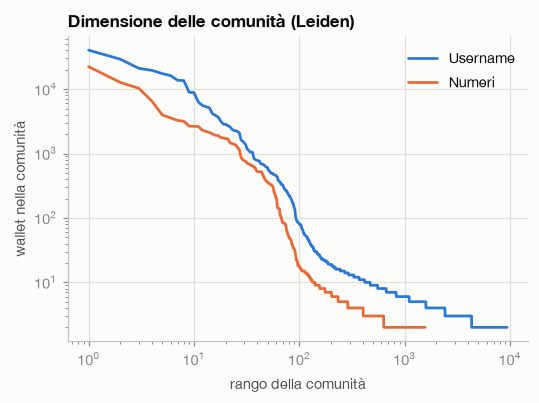

In [7]:
fig, ax = plt.subplots(figsize=(5.4, 3.6))
for l in LAYERS:
    dim = np.bincount(PARTIZIONI[(PRINCIPALE, l)][1])
    ax.loglog(np.arange(1, len(dim) + 1), dim, color=COLORI[l], label=NOME[l], linewidth=1.8)
ax.set_xlabel('rango della comunità')
ax.set_ylabel('wallet nella comunità')
ax.set_title('Dimensione delle comunità (Leiden)')
ax.legend()
salva_figura(fig, 'c_comunita_dimensioni')
plt.show()

## 4. Categorie nelle comunità

Per ogni comunità si guarda quali NFT sono passati dai suoi wallet (un NFT conta se un wallet della comunità lo ha ceduto o ricevuto).
* **Multi-label**: un NFT con più categorie conta una volta per ogni categoria (indicatori 0/1).
* **Arricchimento** = quota di NFT della comunità con quella categoria / quota nel layer. La heatmap mostra il log2: 0 = come nel resto del layer, +1 = il doppio.
* **Test**: si rimescolano le categorie tra gli NFT del layer, tenendo fissi gli NFT di ogni comunità (*random attribute model*), `N_PERM` volte; p-value empirico corretto con Benjamini-Hochberg. Il punto nella cella indica q < 0,01.
* La tabella salvata riporta anche le frequenze per evento, oltre a quelle per NFT distinto.

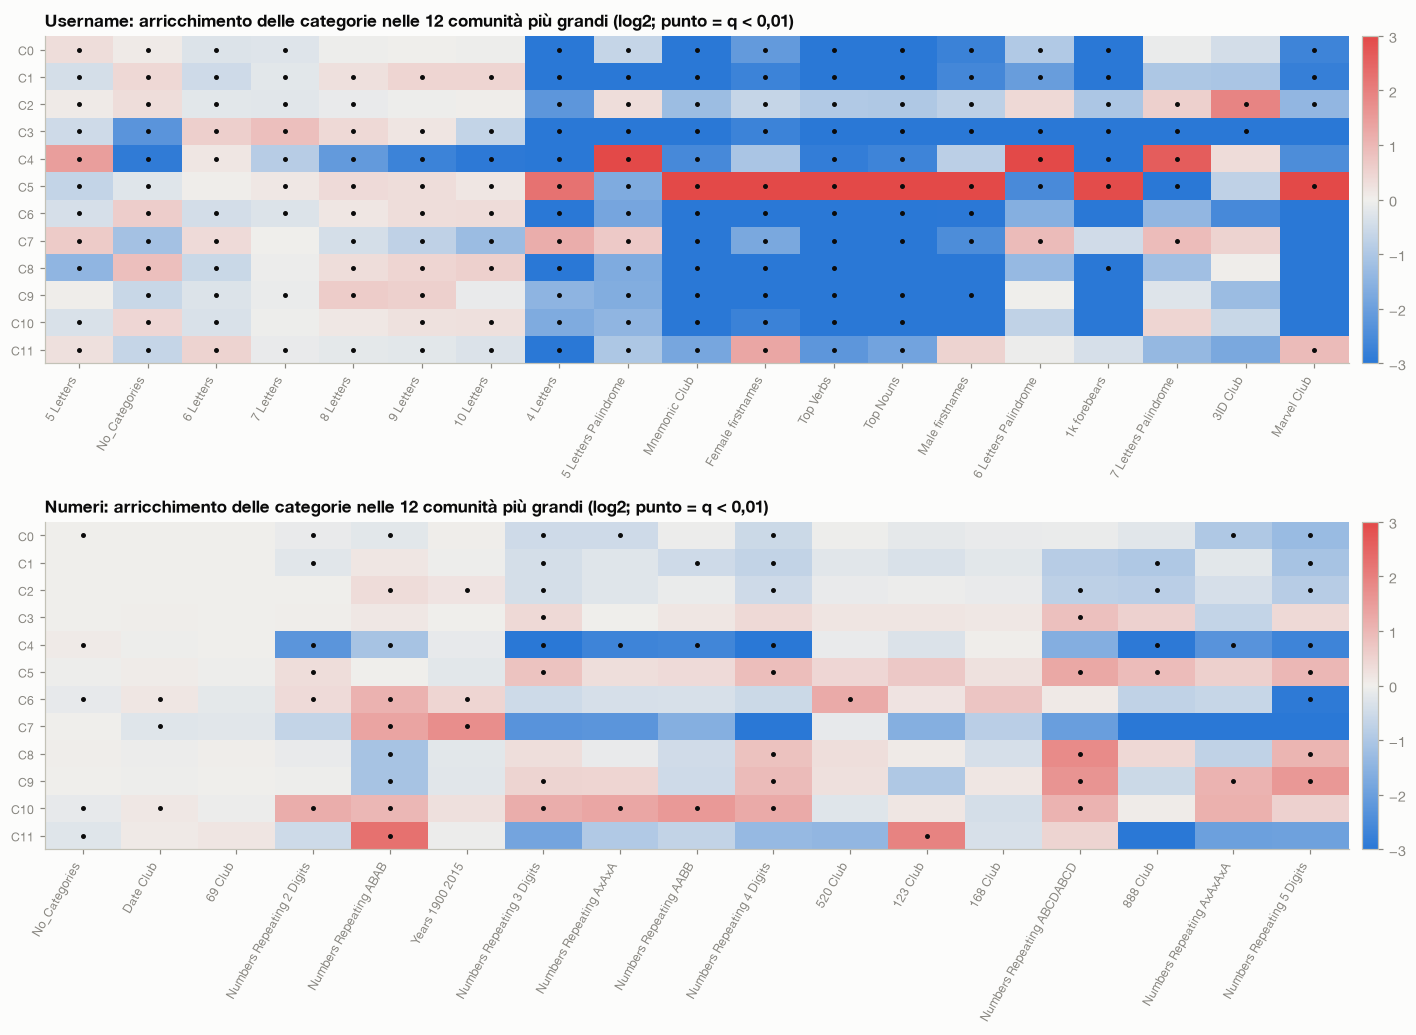

,layer,comunita,categoria,nft_comunita,nft_con_categoria,quota_nel_layer,log2_arricchimento,z,q
375,Username,5,Legendary Pokemon,20677,35,8.991e-05,4.235,25.68,0.006785
367,Username,5,Gen1 pokemon,20677,35,9.248e-05,4.194,25.17,0.006785
393,Username,5,Top Verbs,20677,401,0.001189,4.027,80.49,0.006785
392,Username,5,Top Nouns,20677,353,0.001064,4.005,74.61,0.006785
380,Username,5,Mnemonic Club,20677,852,0.002572,4.002,107.9,0.006785
363,Username,5,Food,20677,106,0.0003314,3.951,37.74,0.006785
362,Username,5,Folklore,20677,42,0.0001516,3.744,23.48,0.006785
374,Username,5,League of Legends Characters,20677,31,0.000113,3.729,19.94,0.006785
348,Username,5,Cartoon Characters,20677,35,0.0001284,3.72,20.36,0.006785
379,Username,5,Marvel Club,20677,146,0.0006037,3.548,42.21,0.006785


In [8]:
cat_nft = pd.read_parquet(DATI / 'fragment_final.parquet', columns=['nft', 'layer', 'categories']).drop_duplicates('nft')
eventi = pd.read_parquet(cartella_variante(PRINCIPALE) / 'transfer_events.parquet', columns=['layer', 'nft', 'src', 'dst', 'tipo_riga', 'ts', 'is_purchase', 'price_ton'])
passaggi = eventi[eventi.tipo_riga == 'A -> B'].reset_index(drop=True)

def legami_comunita(layer):
    u, m = PARTIZIONI[(PRINCIPALE, layer)]
    comunita = pd.Series(m, index=u.vs['name'])
    p = passaggi[passaggi.layer == layer]
    lunga = pd.concat([pd.DataFrame({'evento': p.index, 'nft': p.nft, 'comunita': p.src.map(comunita)}),
                       pd.DataFrame({'evento': p.index, 'nft': p.nft, 'comunita': p.dst.map(comunita)})]).dropna()
    return lunga.astype({'comunita': int}).drop_duplicates(['evento', 'comunita']), comunita

def arricchimento(layer, n_perm=N_PERM):
    legami, _ = legami_comunita(layer)
    legami = legami[legami.comunita < TOP_COMUNITA]
    c = cat_nft[cat_nft.layer == layer]
    # base: gli NFT del layer con almeno un passaggio, le uniche che possono entrare in una comunità
    nft = pd.Index(passaggi.loc[passaggi.layer == layer, 'nft'].unique())
    c = c.set_index('nft').categories.reindex(nft)
    esplosa = c.explode()
    nomi_cat = sorted(esplosa.dropna().unique())
    i_cat = pd.Index(nomi_cat)
    C = sp.csr_matrix((np.ones(len(esplosa)), (nft.get_indexer(esplosa.index), i_cat.get_indexer(esplosa))), shape=(len(nft), len(nomi_cat)))
    distinti = legami.drop_duplicates(['comunita', 'nft'])
    B = sp.csr_matrix((np.ones(len(distinti)), (distinti.comunita, nft.get_indexer(distinti.nft))), shape=(TOP_COMUNITA, len(nft)))
    Bev = sp.csr_matrix((np.ones(len(legami)), (legami.comunita, nft.get_indexer(legami.nft))), shape=(TOP_COMUNITA, len(nft)))
    conta = (B @ C).toarray()
    conta_ev = (Bev @ C).toarray()
    n_c = np.asarray(B.sum(axis=1)).ravel()[:, None]
    n_ev = np.asarray(Bev.sum(axis=1)).ravel()[:, None]
    quota_layer = np.asarray(C.sum(axis=0)).ravel() / len(nft)
    rng = np.random.default_rng(SEED)
    somma, somma2, estremi = np.zeros_like(conta), np.zeros_like(conta), np.zeros_like(conta)
    atteso = n_c * quota_layer
    for _ in range(n_perm):
        pc = (B @ C[rng.permutation(len(nft))]).toarray()
        somma += pc; somma2 += pc ** 2
        estremi += np.abs(pc - atteso) >= np.abs(conta - atteso)
    sd = np.sqrt(np.maximum(somma2 / n_perm - (somma / n_perm) ** 2, 0))
    with np.errstate(divide='ignore', invalid='ignore'):
        lg = np.log2((conta / n_c) / quota_layer)
        lg_ev = np.log2((conta_ev / n_ev) / quota_layer)
        z = (conta - somma / n_perm) / sd
    p = (1 + estremi) / (1 + n_perm)
    r = pd.DataFrame({'layer': layer, 'comunita': np.repeat(np.arange(TOP_COMUNITA), len(nomi_cat)), 'categoria': nomi_cat * TOP_COMUNITA,
                      'nft_comunita': n_c.repeat(len(nomi_cat)).astype(int), 'nft_con_categoria': conta.ravel().astype(int),
                      'eventi_con_categoria': conta_ev.ravel().astype(int), 'quota_nel_layer': np.tile(quota_layer, TOP_COMUNITA),
                      'log2_arricchimento': lg.ravel(), 'log2_arricchimento_eventi': lg_ev.ravel(), 'z': z.ravel(), 'p': p.ravel()})
    r['q'] = benjamini_hochberg(r.p)
    r['nft_categoria_layer'] = (r.quota_nel_layer * len(nft)).round().astype(int)
    return r

ENR = pd.concat([arricchimento(l) for l in LAYERS], ignore_index=True)
salva_tabella(ENR, 'c_arricchimento_categorie', index=False)

blu_rosso = LinearSegmentedColormap.from_list('bluerosso', ['#2a78d6', '#f0efec', '#e34948'])
fig, axes = plt.subplots(2, 1, figsize=(13, 9.5))
for ax, l in zip(axes, LAYERS):
    r = ENR[(ENR.layer == l) & (ENR.nft_categoria_layer >= MIN_NFT_CAT)]
    ordine = r.drop_duplicates('categoria').sort_values('nft_categoria_layer', ascending=False).categoria.tolist()
    mat = r.pivot(index='comunita', columns='categoria', values='log2_arricchimento')[ordine]
    q = r.pivot(index='comunita', columns='categoria', values='q')[ordine]
    im = ax.imshow(mat.clip(-3, 3).fillna(-3), vmin=-3, vmax=3, cmap=blu_rosso, aspect='auto')
    ax.set_xticks(range(len(ordine)), ordine, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(TOP_COMUNITA), [f'C{i}' for i in range(TOP_COMUNITA)], fontsize=8)
    ax.grid(False)
    yy, xx = np.where(q.to_numpy() < 0.01)
    ax.scatter(xx, yy, s=5, color=INK)
    ax.set_title(f'{NOME[l]}: arricchimento delle categorie nelle {TOP_COMUNITA} comunità più grandi (log2; punto = q < 0,01)')
    fig.colorbar(im, ax=ax, fraction=0.015, pad=0.01)
fig.tight_layout()
salva_figura(fig, 'c_arricchimento_heatmap')
plt.show()
visibili = ENR[(ENR.q < 0.01) & (ENR.nft_con_categoria >= 30) & (ENR.categoria != 'No_Categories')]
visibili.assign(layer=visibili.layer.map(NOME)).sort_values('log2_arricchimento', ascending=False).groupby('layer').head(10)[['layer', 'comunita', 'categoria', 'nft_comunita', 'nft_con_categoria', 'quota_nel_layer', 'log2_arricchimento', 'z', 'q']]

## 5. Profili delle comunità

Per ognuna delle comunità più grandi:
* **entropia delle categorie** (normalizzata tra 0 e 1), su NFT distinti: 0 = una sola categoria, 1 = categorie equidistribuite;
* **prezzo mediano** delle vendite con prezzo a cui partecipa la comunità;
* **tempo di possesso mediano**, sui soli periodi conclusi (`COMPLETE`);
* **attività**: passaggi per wallet per mese osservato;
* **quota di vendite** sul totale dei passaggi.

wallet  NFT distinti  passaggi categoria più frequente  entropia categorie  prezzo mediano (TON)  possesso mediano (giorni)  passaggi per wallet al mese  quota vendite  mesi osservati
layer    comunita                                                                                                                                                                                         
Username C0         40366         85539    243040               5 Letters              0.4909                     6                      1.913                       0.1278         0.5545           47.11
         C1         29178         34825    176526           No_Categories               0.551                     6                      2.905                       0.1284         0.1488           47.11
         C2         21024         53425    110252               5 Letters              0.5087                     7                       12.2                        0.111         0.5785           47.24
         C3         19566         20335     71332               7 Letters              0.5918                     7                      6.025                      0.08457        0.03126           43.11
         C4         17433         18182    127985               5 Letters              0.3574                     8                      3.687                       0.1565         0.0555           46.91
         C5         16218         20677     71913               6 Letters              0.6127                    49                      15.53                       0.0935           0.13           47.42
         C6         13710         18079     71064           No_Categories              0.5918                  5.97                     0.3239                        0.111          0.279           46.71
         C7         13614         31710     98598               5 Letters              0.4903                     8                      6.873                       0.1545         0.1275           46.87
         C8          8957          9106     45057           No_Categories              0.6626                     6                      6.965                       0.1068        0.07062           47.08
         C9          8831         22523     42745               5 Letters              0.5901                     7                      8.395                       0.1043         0.4616           46.39
         C10         6310         11764     35873           No_Categories              0.6274                  5.99                      3.859                       0.1236         0.4269           46.01
         C11         5601         31378     57406               5 Letters              0.4809                    19                      67.77                       0.2157         0.2983           47.51
Numeri   C0         22333         53733    120558           No_Categories              0.4062                    43                      32.39                       0.1161         0.8369           46.49
         C1         12704         20354     70862           No_Categories              0.4095                   860                     0.8981                         0.12         0.5018           46.49
         C2         10302         21405     54755           No_Categories               0.424                   176                      18.94                       0.1143         0.6492           46.49
         C3          6483         15791     68079           No_Categories               0.442                   745                      1.713                       0.2259         0.1662           46.49
         C4          3972          8790     19584           No_Categories              0.3555                   135                      232.5                       0.1061         0.5792           46.49
         C5          3577          9300     41949           No_Categories              0.4643                   180                       5.25                    

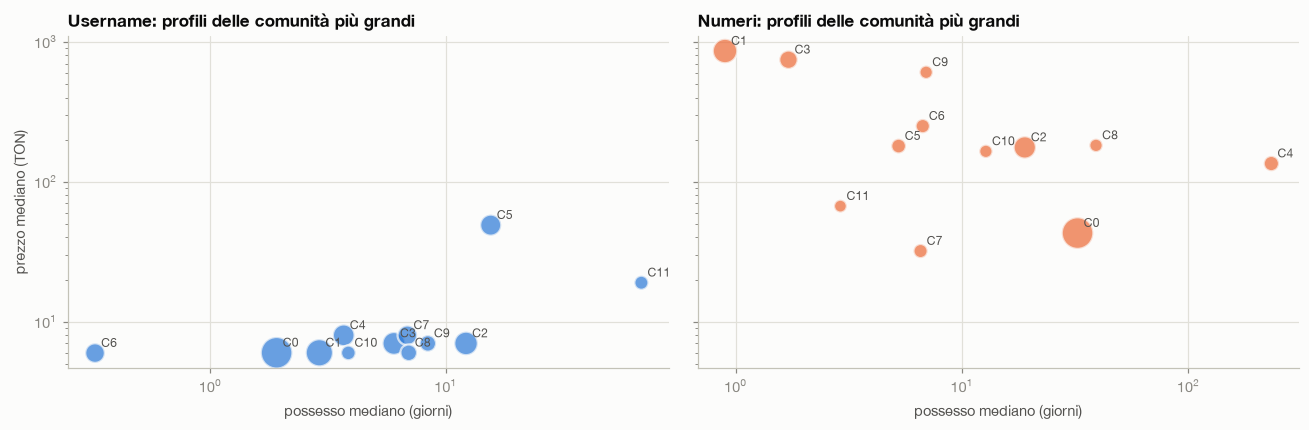

In [9]:
possessi = pd.read_parquet(cartella_variante(PRINCIPALE) / 'holding_periods.parquet', columns=['layer', 'wallet', 'nft', 'status', 'holding_days'])
FINE = eventi.ts.max()
righe = []
for l in LAYERS:
    legami, comunita = legami_comunita(l)
    p = passaggi.loc[legami.evento.unique()]
    c = cat_nft[cat_nft.layer == l].set_index('nft').categories
    dim = comunita.value_counts()
    poss = possessi[(possessi.layer == l) & (possessi.status == 'COMPLETE')]
    poss = poss.assign(comunita=poss.wallet.map(comunita)).dropna(subset='comunita')
    d_med = poss.groupby('comunita').holding_days.median()
    ts_primo = passaggi.loc[passaggi.layer == l].ts.min()
    for i in range(TOP_COMUNITA):
        ev = passaggi.loc[legami.loc[legami.comunita == i, 'evento']]
        nft = ev.nft.unique()
        frequenze = c.reindex(nft).explode().value_counts()
        q = frequenze / frequenze.sum()
        mesi = max(1.0, (ev.ts.max() - ev.ts.min()).total_seconds() / (86400 * 30.44))
        righe.append({'layer': NOME[l], 'comunita': f'C{i}', 'wallet': int(dim[i]), 'NFT distinti': len(nft), 'passaggi': len(ev),
                      'categoria più frequente': frequenze.index[0],
                      'entropia categorie': -(q * np.log(q)).sum() / np.log(len(q)) if len(q) > 1 else 0.0,
                      'prezzo mediano (TON)': ev.price_ton.median(), 'possesso mediano (giorni)': d_med.get(i, np.nan),
                      'passaggi per wallet al mese': len(ev) / dim[i] / mesi, 'quota vendite': ev.is_purchase.mean(), 'mesi osservati': mesi})
PROFILI = pd.DataFrame(righe).set_index(['layer', 'comunita'])
salva_tabella(PROFILI, 'c_profili_comunita')
display(PROFILI)

fig, axes = plt.subplots(1, len(LAYERS), figsize=(6 * len(LAYERS), 4), sharey=True)
for ax, l in zip(axes, LAYERS):
    r = PROFILI.loc[NOME[l]]
    ax.scatter(r['possesso mediano (giorni)'], r['prezzo mediano (TON)'], s=30 + 400 * r['wallet'] / r['wallet'].max(), color=COLORI[l], alpha=0.7,
               edgecolors=SUPERFICIE, linewidths=1.5)
    for nome, x in r.iterrows():
        ax.annotate(nome, (x['possesso mediano (giorni)'], x['prezzo mediano (TON)']), fontsize=8, color=SECONDARIO, xytext=(4, 4), textcoords='offset points')
    ax.set_xscale('symlog', linthresh=0.1); ax.set_yscale('log')
    ax.set_xlabel('possesso mediano (giorni)')
    ax.set_title(f'{NOME[l]}: profili delle comunità più grandi')
axes[0].set_ylabel('prezzo mediano (TON)')
fig.tight_layout()
salva_figura(fig, 'c_profili_comunita')
plt.show()

## 6. Lettura (RQ1)

Valori sulla rete senza contratti, username / numeri.

* **Due reti con la stessa forma.** Componente gigante molto ampia (92% / 98% dei wallet con archi), gradi a coda pesante, forte concentrazione: il top 1% dei wallet genera il 37% / 50% della forza, il top 10% il 69% / 78%. I numeri sono un po' più concentrati (Gini 0,75 / 0,80).
* **La struttura non si spiega con i soli gradi.** La reciprocità (0,18 / 0,17) e la modularità (0,80 / 0,68) sono molto sopra il configuration model (0,02 / 0,05 e 0,26 / 0,23). Il clustering è sopra il nullo soprattutto negli username (0,11 contro 0,05); nei numeri la differenza è piccola (0,116 contro 0,107).
* **Hub.** Le classifiche dipendono dalla metrica: tra metriche diverse il Jaccard dei top 100 va da 0,19 a 0,74. Conta anche la rimozione dei contratti: per il PageRank il Jaccard tra le due reti è 0,49 negli username e 0,77 nei numeri. Nella rete completa la reciprocità degli username sale a 0,42, ed è un effetto dei noleggi.
* **Comunità.** Leiden trova partizioni con modularità alta, ma il dettaglio non è molto stabile: con un altro seed NMI 0,83 / 0,70, con Louvain 0,79 / 0,62. Sono affidabili le comunità grandi e il quadro generale, non i confini delle singole comunità.
* **Categorie.** Le comunità non sono divise nettamente per categoria, ma alcune hanno un profilo chiaro. Negli username la C5 è arricchita di circa 16 volte in parole di dizionario e nomi (Top Verbs, Top Nouns, Mnemonic Club, Marvel Club) e ha un prezzo mediano di 49 TON, contro 6-8 TON della maggior parte delle altre grandi comunità. La C4 è arricchita in palindromi. Nei numeri gli arricchimenti sono più bassi: al massimo circa 9 volte (C9, Numbers Length 7) e circa 5 volte per la C11 (ABAB).
* **Profili.** I prezzi separano bene le comunità dei numeri: da circa 32 TON (C7) a 860 TON (C1). Le comunità con i prezzi più alti hanno anche i possessi più brevi (C1: mediana 0,9 giorni), mentre la C4 ha possessi di 232 giorni.